# Function 8 - Week 5: Model Predictions

#### Model Predictions using Official Observations up to and including Week 4 return, received on **23 October 2026**.

Read [the Week 5 report](report.md) for model interpretation, query selection and limitations.

In [1]:
%matplotlib inline

# Imports and shared helpers.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "model_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review
from model_review_helpers import (
    make_regression_models, fit_model_review, review_latest_predictions,
    build_review_candidates, score_review_candidates,
    query_prediction, weight_sensitivity, noise_sensitivity,
)
from model_review_plots import plot_held_out_comparison, plot_latest_predictions
from coverage_cache import compare_coverage_batches
from query_budget import remaining_queries
from plot_helpers import PLOT_CONFIG
from model_review_plots import plot_coordinate_model_review
# Require the shared Capstone environment, even if another kernel was selected.
repository_dir = next(folder for folder in Path.cwd().parents if (folder / "run-python.ps1").is_file())
expected_interpreter = repository_dir / ".venv" / "Scripts" / "python.exe"
if Path(sys.executable).resolve() != expected_interpreter.resolve():
    raise RuntimeError(f"Select the Capstone kernel: {expected_interpreter}")
print(f"Python interpreter: {sys.executable}")


Python interpreter: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Settings for this run. Keep model assumptions and search settings here.
FUNCTION_NUMBER = 8
CURRENT_WEEK = 5
INPUT_COLUMNS = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8']
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 40, 1: 1, 2: 1, 3: 1, 4: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK}"
PORTAL_DECIMALS = 6
MODEL_NAMES = ["Mean baseline", "Linear regression", "Ridge", "Kernel ridge", "Gaussian process"]
GP_NAMES = ["Gaussian process"]
# Retain the existing GP diagonal regularisation; it is not a measured noise level.
MODEL_SETTINGS = dict(
    noise_fraction=0.10, ridge_alpha=1.0,
    kernel_ridge_alpha=0.1, kernel_ridge_gamma=1.0,
    length_scale=0.3, length_scale_bounds=(0.03, 2.0),
    amplitude=1.0, amplitude_bounds=(0.01, 100.0), optimiser_restarts=3, seed=42,
)
EXPLORATION_WEIGHT = 1.96
SEARCH_SETTINGS = dict(
    broad_power=14, broad_seed=42, local_power=12, local_seed=43,
    local_radius=0.15, precision=PORTAL_DECIMALS, include_corners=True,
)
COVERAGE_SETTINGS = dict(
    max_queries=1, optimization_power=12, evaluation_power=15,
    optimization_seed=42, evaluation_seed=43, comparison_seed=42, verbose=False,
)
EXPLORATION_WEIGHTS = (0.0, 1.0, 1.96, 3.0)
VALIDATION_MODELS = ["Ridge", "Kernel ridge"]
COORDINATE_VIEW_SETTINGS = dict(side=250, padding_fraction=0.05, figsize=(36.0, 5.3))
CANDIDATES_TO_SHOW = 5
VALIDATION_SIZE = (15, 5)
LATEST_RESULT_SIZE = (11, 5.5)
REGULARISATION_FRACTIONS = (0.03, 0.10, 0.30)


In [3]:
# Validate the same snapshot used by the exploration review.
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
inputs = review["inputs"].to_numpy(dtype=float)
raw_y = review["outputs"].to_numpy(dtype=float)
anchor = inputs[int(np.argmax(raw_y))].copy()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))

,observation_id,source_round,x1,x2,x3,x4,x5,x6,x7,x8,y,output_rank
43,round-04,4,0.0,0.999999,0.0,0.0,0.999999,0.999999,0.0,0.999999,8.818303,10


In [4]:
# Fit each complete estimator within every held-out fold.
models = make_regression_models(len(INPUT_COLUMNS), **MODEL_SETTINGS)
models = {name: models[name] for name in MODEL_NAMES}
model_run = fit_model_review(models, inputs, raw_y, gp_names=GP_NAMES)
selected_model = model_run["selected_model"]
modelled_axes = tuple(range(len(INPUT_COLUMNS)))
display(model_run["table"].round(6))
display(pd.Series({"Selected GP": model_run["selected_name"], "Fitted kernel": model_run["fitted_kernel"]}))

,Model,Training MAE,LOO MAE,LOO RMSE,MAE / baseline,RMSE reduction (%)
0,Gaussian process,0.026314,0.244826,0.315459,0.289521,68.783535
1,Ridge,0.355072,0.428428,0.527168,0.506641,47.833816
2,Linear regression,0.337119,0.437936,0.550326,0.517885,45.542162
3,Mean baseline,0.826407,0.845625,1.010554,1.000000,0.000000
4,Kernel ridge,0.226342,1.184564,1.810039,1.400814,-79.113530


Selected GP                      Gaussian process
Fitted kernel    1.58**2 * RBF(length_scale=1.28)
dtype: str

,Model,Latest held-out prediction,Latest error,Latest absolute error (%),Latest share of squared error (%),Other rows LOO RMSE
0,Gaussian process,9.4898,0.6715,7.6153,10.2992,0.3022
1,Ridge,9.6328,0.8145,9.2366,5.4255,0.5186
2,Mean baseline,7.9169,-0.9014,10.2222,1.8084,1.0130
3,Linear regression,10.0889,1.2706,14.4083,12.1145,0.5219
4,Kernel ridge,3.7464,-5.0719,57.5158,17.8450,1.6596


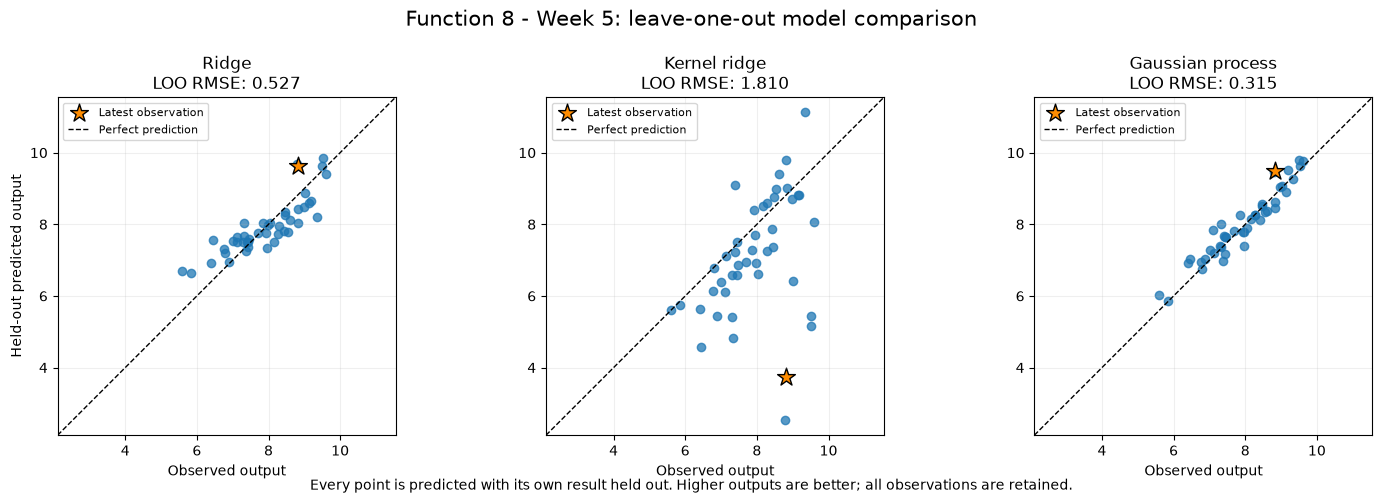

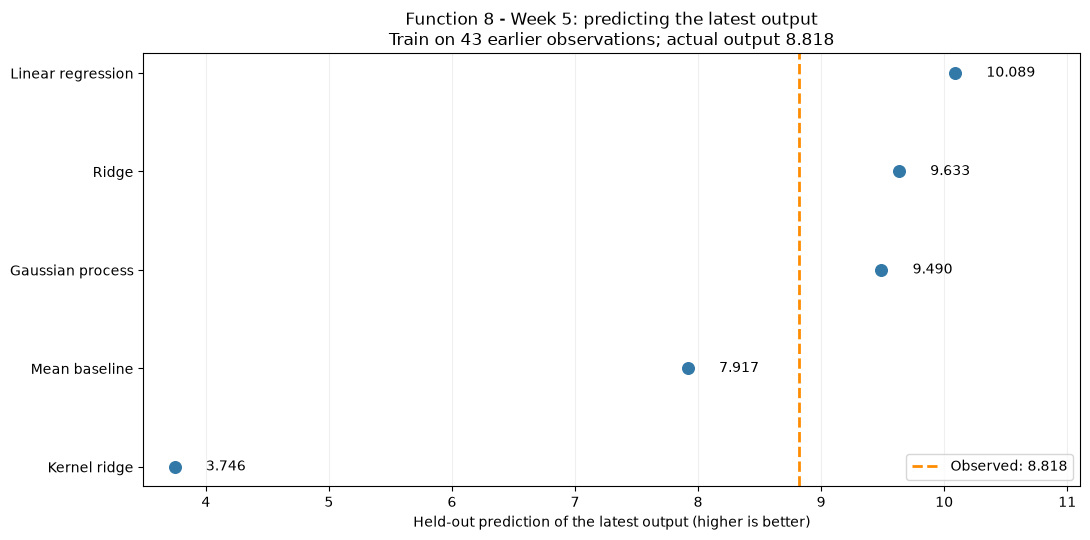

In [5]:
# This checks the latest held-out result retrospectively; it is not a saved forecast.
latest_review = review_latest_predictions(model_run["predictions"], raw_y, review["latest_mask"])
latest_output = float(raw_y[review["latest_mask"]][0])
display(latest_review.round(4))
display(plot_held_out_comparison(
    model_run["predictions"], raw_y,
    model_names=[*VALIDATION_MODELS, model_run["selected_name"]], latest_mask=review["latest_mask"],
    title=f"{TITLE}: leave-one-out model comparison", figsize=VALIDATION_SIZE,
    save_to=FIGURES_DIR / "model-comparison-validation.png",
))
display(plot_latest_predictions(
    latest_review, latest_output, n_training_rows=int((~review["latest_mask"]).sum()),
    title=f"{TITLE}: predicting the latest output", figsize=LATEST_RESULT_SIZE,
    save_to=FIGURES_DIR / "latest-output-predictions.png",
))

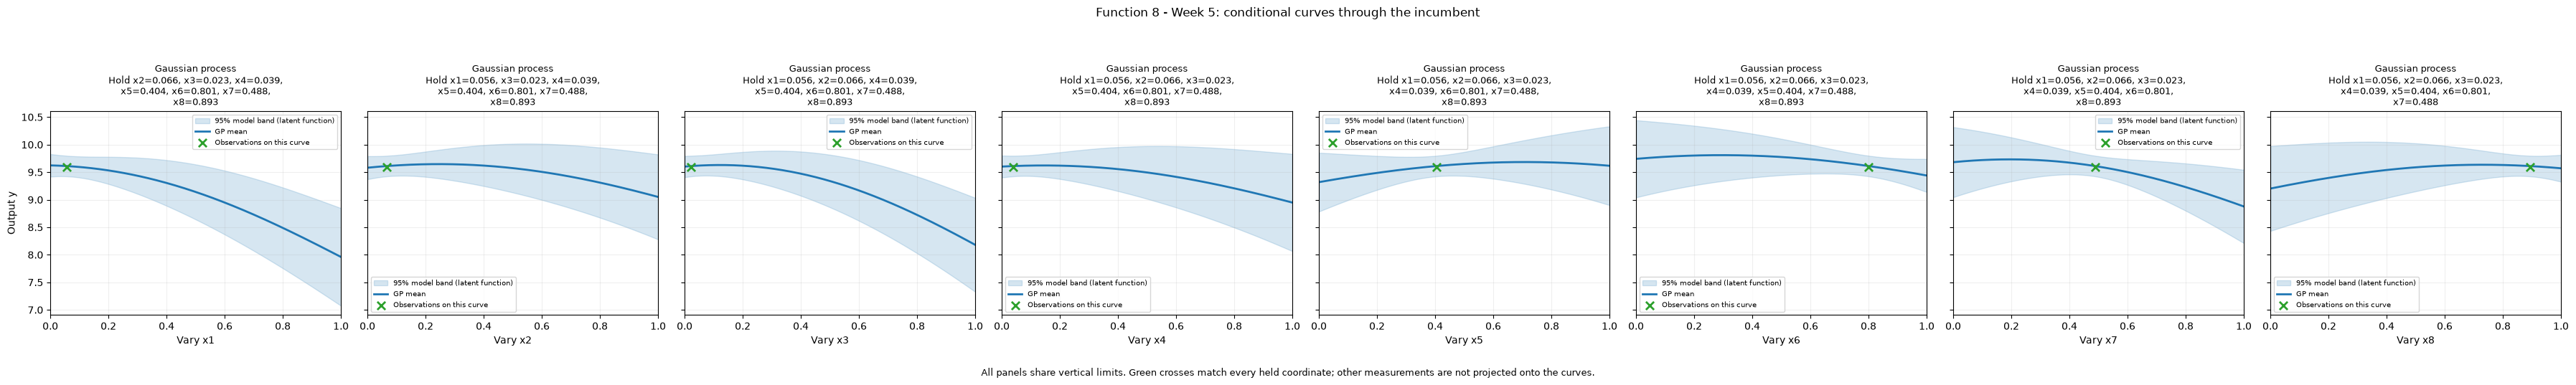

In [6]:
# Vary one coordinate at a time through the measured incumbent, holding all others fixed.
coordinate_figure = plot_coordinate_model_review(
    {name: model_run["fitted"][name] for name in GP_NAMES}, inputs, raw_y, anchor,
    input_columns=INPUT_COLUMNS, title=f"{TITLE}: conditional curves through the incumbent",
    **COORDINATE_VIEW_SETTINGS, save_to=None,
)
# Wrap the held-coordinate settings so the higher-dimensional panels remain readable.
from textwrap import fill
for coordinate_axis in coordinate_figure.axes:
    model_label, held_settings = coordinate_axis.get_title().split("\n", 1)
    coordinate_axis.set_title(model_label + "\n" + fill(held_settings, width=34), fontsize=9)
coordinate_figure.tight_layout(rect=(0, 0.06, 1, 0.92))
coordinate_figure.savefig(FIGURES_DIR / "gp-coordinate-slices.png", dpi=160, bbox_inches="tight")
display(coordinate_figure)


In [7]:
# Reuse the geometric coverage cache, then score the exact rounded candidate inputs.
coverage = compare_coverage_batches(
    existing=inputs, cache_dir=ANALYSIS_DIR / ".coverage-cache", **COVERAGE_SETTINGS,
)
candidates = build_review_candidates(
    inputs, anchor, coverage["proposed_batches"][1], input_columns=INPUT_COLUMNS, **SEARCH_SETTINGS,
)
# Retain a separate local search around the latest returned corner, as in Week 4.
latest_anchor = inputs[np.flatnonzero(review["latest_mask"])[0]]
latest_candidates = build_review_candidates(
    inputs, latest_anchor, coverage["proposed_batches"][1],
    input_columns=INPUT_COLUMNS, **SEARCH_SETTINGS,
)
latest_candidates = latest_candidates.loc[latest_candidates.candidate_source.eq("Near incumbent")].copy()
latest_candidates["candidate_source"] = "Near latest return"
candidates = pd.concat([candidates, latest_candidates], ignore_index=True).drop_duplicates(subset=INPUT_COLUMNS)
scored = score_review_candidates(
    selected_model, candidates, input_columns=INPUT_COLUMNS,
    weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
by_source = scored.loc[scored.groupby("candidate_source")["ucb"].idxmax()].sort_values("ucb", ascending=False)
display(by_source.round(6))
display(pd.DataFrame(coverage["results"]))

,x1,x2,x3,x4,x5,x6,x7,x8,posterior_mean,posterior_sd,ucb,candidate_source
0,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.999999,9.432307,0.588048,10.584882,Full input space
89,0.000000,0.215955,0.00000,0.188786,0.553935,0.651055,0.338307,0.743085,9.940224,0.180609,10.294217,Near incumbent
2267,0.139599,0.140131,0.14216,0.679746,0.654662,0.690608,0.522666,0.947401,9.356225,0.293423,9.931334,Single coverage query
5823,0.000000,0.849999,0.00000,0.150000,0.849999,0.849999,0.150000,0.849999,9.352503,0.178968,9.703280,Near latest return


,q,max_distance,p95_distance
0,0,1.312582,0.809420
1,1,1.309326,0.807622


In [8]:
# Every coordinate remains free in the rounded candidate comparison.
recommended = scored.iloc[0]
next_query = recommended[INPUT_COLUMNS].to_numpy(dtype=float)
proposal = query_prediction(
    selected_model, next_query, inputs, raw_y, weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
proposal_source = recommended.candidate_source
display(pd.Series(proposal))

point                             [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.999999]
predicted_output                                                       9.432307
posterior_std                                                          0.588048
ucb                                                                   10.584882
predicted_mean_improvement                                            -0.166175
inside_sampled_hull                                                       False
portal_input                  0.000000-0.000000-0.000000-0.000000-0.000000-0...
dtype: object

In [9]:
# Reuse the same candidate pool and predictions while changing the exploration weight.
exploration_sensitivity = weight_sensitivity(
    scored, inputs, input_columns=INPUT_COLUMNS, modelled_axes=modelled_axes,
    weights=EXPLORATION_WEIGHTS, precision=PORTAL_DECIMALS,
)
display(exploration_sensitivity.round(6))

,Weight,x1,x2,x3,x4,x5,x6,x7,x8,Predicted output,Posterior SD
0,0.00,0.04059,0.201266,0.004758,0.175232,0.482420,0.456175,0.220741,0.705113,10.030597,0.206020
1,1.00,0.25336,0.262644,0.070249,0.077138,0.511387,0.389897,0.039989,0.503902,10.017733,0.260173
2,1.96,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.999999,9.432307,0.588048
3,3.00,0.00000,0.999999,0.000000,0.999999,0.999999,0.000000,0.000000,0.000000,8.902421,0.767888


In [10]:
# Retain every coordinate in the alternatives; these predictions are not measured outputs.
display(scored.head(CANDIDATES_TO_SHOW)[[
    *INPUT_COLUMNS, "posterior_mean", "posterior_sd", "ucb", "candidate_source",
]].round(PORTAL_DECIMALS))

,x1,x2,x3,x4,x5,x6,x7,x8,posterior_mean,posterior_sd,ucb,candidate_source
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.999999,9.432307,0.588048,10.584882,Full input space
1,0.253360,0.262644,0.070249,0.077138,0.511387,0.389897,0.039989,0.503902,10.017733,0.260173,10.527671,Full input space
2,0.156520,0.064646,0.086941,0.086229,0.381447,0.467821,0.008908,0.281191,9.848396,0.337018,10.508951,Full input space
3,0.050308,0.523110,0.059738,0.199458,0.627842,0.214082,0.028552,0.500147,9.953082,0.277607,10.497193,Full input space
4,0.022327,0.096114,0.237034,0.202848,0.982361,0.880106,0.159960,0.678158,9.780936,0.355580,10.477873,Full input space


In [11]:
# Check the same input under alternative GP diagonal regularisation assumptions.
# These fractions do not estimate repeat-evaluation noise or reselect the query.
regularisation_sensitivity = noise_sensitivity(
    selected_model, inputs, raw_y, next_query, fractions=REGULARISATION_FRACTIONS,
    fitted_noise_fraction=MODEL_SETTINGS["noise_fraction"],
)
display(regularisation_sensitivity.round(6))


,Assumed noise fraction,Predicted output,Posterior SD
0,0.03,9.342683,0.599519
1,0.10,9.432307,0.588048
2,0.30,9.653110,0.587901


In [12]:
# Save the Week 5 proposal and its review evidence; no portal request is made.
analysis_summary = {
    "python_executable": sys.executable,
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(raw_y),
    "query_model": model_run["selected_name"], "proposal_status": "proposed_not_submitted",
    "portal_input": proposal["portal_input"], "point": proposal["point"],
    "predicted_output": proposal["predicted_output"], "posterior_std": proposal["posterior_std"],
    "ucb_weight": EXPLORATION_WEIGHT, "candidate_source": proposal_source,
    "candidate_count": len(scored),
    "inside_sampled_hull": proposal["inside_sampled_hull"], "best_observed_output": float(raw_y.max()),
    "gp_rmse": model_run["selected_rmse"], "baseline_rmse": model_run["baseline_rmse"],
    "gp_baseline_rmse_ratio": model_run["selected_rmse"] / model_run["baseline_rmse"],
    "lowest_rmse_model": model_run["table"].iloc[0]["Model"],
    "distinct_weight_choices": len(exploration_sensitivity[INPUT_COLUMNS].drop_duplicates()),
    "remaining_queries": remaining_queries(WEEK_DIR),
    "model_comparison": model_run["table"].to_dict(orient="records"),
    "fitted_kernel": model_run["fitted_kernel"],
    "length_scales": np.atleast_1d(selected_model.kernel_.k2.length_scale).tolist(),
    "weight_sensitivity": exploration_sensitivity.to_dict(orient="records"),
    "regularisation_sensitivity": regularisation_sensitivity.to_dict(orient="records"),
    "proposal": proposal,
    "latest_prediction_review": latest_review.to_dict(orient="records"),
    "coverage_comparison": pd.DataFrame(coverage["results"]).to_dict(orient="records"),
    "candidate_source_comparison": by_source.to_dict(orient="records"),
    "snapshot_round_counts": EXPECTED_ROUND_COUNTS,
    "model_settings": MODEL_SETTINGS, "search_settings": SEARCH_SETTINGS,
}
print(json.dumps(analysis_summary, indent=2))

{
  "python_executable": "C:\\_Source\\Imperial-ML-AI-Live\\Capstone\\imperial-capstone\\.venv\\Scripts\\python.exe",
  "function": 8,
  "week": 5,
  "observations": 44,
  "query_model": "Gaussian process",
  "proposal_status": "proposed_not_submitted",
  "portal_input": "0.000000-0.000000-0.000000-0.000000-0.000000-0.000000-0.000000-0.999999",
  "point": [
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.999999
  ],
  "predicted_output": 9.432307195025363,
  "posterior_std": 0.5880482857438927,
  "ucb_weight": 1.96,
  "candidate_source": "Full input space",
  "candidate_count": 25324,
  "inside_sampled_hull": false,
  "best_observed_output": 9.598482002566342,
  "gp_rmse": 0.3154592616784588,
  "baseline_rmse": 1.01055409203103,
  "gp_baseline_rmse_ratio": 0.31216464726241716,
  "lowest_rmse_model": "Gaussian process",
  "distinct_weight_choices": 4,
  "remaining_queries": 9,
  "model_comparison": [
    {
      "Model": "Gaussian process",
      "Training MAE": 0.0